In [ ]:
import sys

sys.path.append("..")

In [ ]:
import time

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score
from tqdm import tqdm

from src.two_means import numba_two_means_warmup, two_means_pca_threshold
from src.two_means_random_qr import two_means_random_qr_threshold

numba_two_means_warmup()

100%|██████████| 10/10 [00:00<00:00, 11.66it/s]


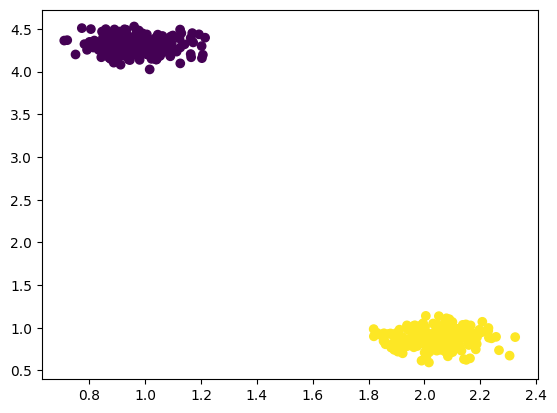

In [ ]:
def make_data(N: int = 400, seed: int = 0):
    x, y = make_blobs(
        n_samples=N,
        centers=2,
        n_features=2,
        cluster_std=0.1,
        random_state=seed,
    )
    return x, y


# Plot blobs
X, y_true = make_data(N=400, seed=0)
plt.figure()
plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y_true,
    cmap="viridis",
)

N_list = np.logspace(2, 5, 10, dtype=int)
power_iters = [0, 1, 5, 10]
repeats = 3

times_pca = []
times_rqr = {}
ari_pca = []
ari_rqr = {}
for N in tqdm(N_list):
    time_pca_runs = []
    ari_pca_runs = []
    time_rqr_runs = {pi: [] for pi in power_iters}
    ari_rqr_runs = {pi: [] for pi in power_iters}
    for repeat in range(repeats):
        X, y_true = make_data(N=N, seed=repeat)

        start_time = time.perf_counter()
        mu = np.mean(X, axis=0)
        X_centered = X - mu
        y_pred_pca = two_means_pca_threshold(X_centered, mu)
        end_time = time.perf_counter()
        time_pca_runs.append(end_time - start_time)
        ari_pca_runs.append(adjusted_rand_score(y_true, y_pred_pca[0]))

        for pi in power_iters:
            start_time = time.perf_counter()
            mu = np.mean(X, axis=0)
            X_centered = X - mu
            y_pred_rqr = two_means_random_qr_threshold(X_centered, mu, power_iter=pi)
            end_time = time.perf_counter()
            time_rqr_runs[pi].append(end_time - start_time)
            ari_rqr_runs[pi].append(adjusted_rand_score(y_true, y_pred_rqr[0]))
    times_pca.append(np.mean(time_pca_runs))
    ari_pca.append(np.mean(ari_pca_runs))
    for pi in power_iters:
        if pi not in times_rqr:
            times_rqr[pi] = []
            ari_rqr[pi] = []
        times_rqr[pi].append(np.mean(time_rqr_runs[pi]))
        ari_rqr[pi].append(np.mean(ari_rqr_runs[pi]))

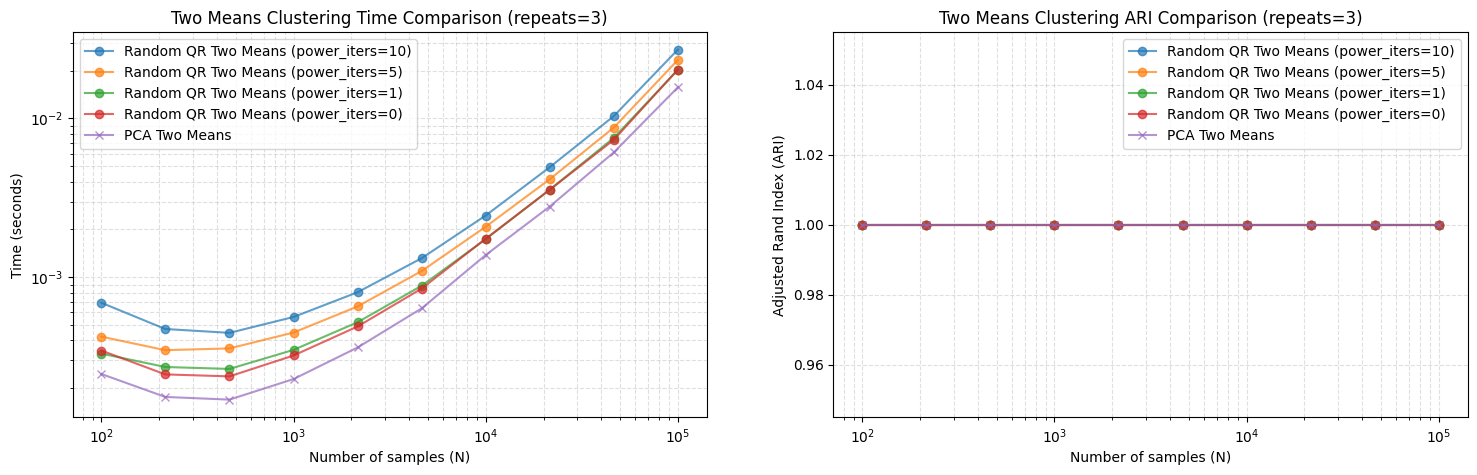

In [ ]:
plt.figure(figsize=(18, 5))
plt.subplot(1, 2, 1)
for pi in reversed(power_iters):
    plt.plot(
        N_list,
        times_rqr[pi],
        label=f"Random QR Two Means (power_iters={pi})",
        marker="o",
        alpha=0.7,
    )
plt.plot(N_list, times_pca, label="PCA Two Means", marker="x", alpha=0.7)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Number of samples (N)")
plt.ylabel("Time (seconds)")
plt.title(f"Two Means Clustering Time Comparison (repeats={repeats})")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)

plt.subplot(1, 2, 2)
for pi in reversed(power_iters):
    plt.plot(
        N_list,
        ari_rqr[pi],
        label=f"Random QR Two Means (power_iters={pi})",
        marker="o",
        alpha=0.7,
    )
plt.plot(N_list, ari_pca, label="PCA Two Means", marker="x", alpha=0.7)
plt.xscale("log")
plt.xlabel("Number of samples (N)")
plt.ylabel("Adjusted Rand Index (ARI)")
plt.title(f"Two Means Clustering ARI Comparison (repeats={repeats})")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)